# 03 · Statistical texture and image pyramids

**Owner:** Member A · **Labs:** 6 (statistical texture: contrast, energy, entropy) and 7 (Gaussian and Laplacian
pyramids) · **Requirements:** REQ-02, REQ-03; spec Section 9.

### Objective
* Compute GLCM descriptors (32 grey levels; distances 1, 2, 4; angles 0°, 45°, 90°, 135°; symmetric, normalised)
  and aggregate them as mean and standard deviation across the 12 offsets.
* Keep **histogram entropy** and **GLCM entropy** as separate, explicitly named features.
* Produce the fixed-schema feature CSV reused by the classifier (notebook 05).
* Build Gaussian/Laplacian pyramids, verify exact reconstruction and show how thin detail vanishes at coarse levels.

Definitions for a normalised GLCM *P*: contrast = Σ(i−j)²P, ASM = ΣP², energy = √ASM,
GLCM entropy = −ΣP log₂P (bits, positive entries), homogeneity = ΣP/(1+(i−j)²), correlation as usual.

In [1]:
%matplotlib inline
from pathlib import Path
import sys

# Robust project-root discovery: works from notebooks/ or the project root, installed or not.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs" / "default.yaml").is_file())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scalptrack.config import load_config, seed_everything, project_path, display_path
from scalptrack.demo_data import dataset_status, development_images, synthetic_closeups, figure_path
import time
import cv2
from skimage.feature import graycomatrix
from scalptrack import texture, pyramids, features as ft
from scalptrack import synthetic as syn
from scalptrack.preprocessing import to_gray
from scalptrack.viz import show_grid

cfg = load_config()
rng = seed_everything(cfg["seed"])
NB = "03_texture_pyramids"
rel = lambda p: display_path(p, ROOT)  # noqa: E731 - short path for printing
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.dpi"] = 90
print("project root:", ROOT)
print("config:", Path(cfg["config_path"]).name, "| seed:", cfg["seed"])

project root: C:\Riddhi_Projects\ScalpTrack
config: default.yaml | seed: 42


In [2]:
def save_fig(fig, name, provenance):
    """Save under outputs/figures/<NB>/<real|synthetic>/ ; synthetic figures get a caption and SYNTHETIC_ prefix."""
    from scalptrack.viz import synthetic_banner

    if provenance == "synthetic":
        synthetic_banner(fig)
    p = figure_path(cfg, NB, name, provenance)
    fig.savefig(p, dpi=120, bbox_inches="tight")
    print("saved", rel(p))
    return p

In [3]:
STATUS = dataset_status(cfg)
print(STATUS["message"])
REAL = STATUS["available"]
DEV = development_images(cfg, n_per_class=1, max_total=4) if REAL else []
SYN = synthetic_closeups(cfg)
print(f"real development images loaded: {len(DEV)} (train/validation only) | synthetic fixtures: {list(SYN)}")

Real dataset 'kaggle_hair_diseases': 12000 image files, manifest at data\manifests\kaggle_hair_diseases_manifest.csv.


real development images loaded: 4 (train/validation only) | synthetic fixtures: ['clean', 'flakes', 'shadow', 'glare', 'light_hair', 'blurred']


## 1. GLCM on one ROI — per-offset table and aggregation

In [4]:
gray = to_gray(SYN["flakes"]["rgb"])
res = texture.glcm_features(
    gray, cfg["texture"]["levels"], cfg["texture"]["distances"], cfg["texture"]["angles_deg"]
)
per = pd.DataFrame(res["per_offset"])
display(per.round(4))
pd.Series(res["aggregate"]).round(4).to_frame("aggregate (12 offsets)")

,distance,angle_deg,n_pairs,contrast,asm,energy,glcm_entropy_bits,homogeneity,correlation
0,1,0,39800,8.6662,0.0995,0.3155,4.6519,0.6287,0.8630
1,1,45,39601,9.1157,0.1002,0.3166,4.7247,0.6315,0.8559
2,1,90,39800,1.1705,0.1116,0.3341,4.3140,0.7593,0.9814
3,1,135,39601,9.1184,0.0996,0.3155,4.7315,0.6291,0.8559
4,2,0,39600,27.7550,0.0891,0.2986,4.9578,0.5719,0.5631
5,2,45,39601,9.1157,0.1002,0.3166,4.7247,0.6315,0.8559
6,2,90,39600,2.6778,0.1077,0.3282,4.4942,0.7261,0.9575
7,2,135,39601,9.1184,0.0996,0.3155,4.7315,0.6291,0.8559
8,4,0,39200,65.2379,0.0692,0.2630,5.3324,0.4952,-0.0184
9,4,45,38809,48.7041,0.0763,0.2762,5.3325,0.5326,0.2366


,aggregate (12 offsets)
glcm_contrast_mean,20.4444
glcm_contrast_std,20.7995
glcm_asm_mean,0.0941
glcm_asm_std,0.0128
glcm_energy_mean,0.3059
glcm_energy_std,0.0215
glcm_entropy_bits_mean,4.8404
glcm_entropy_bits_std,0.3214
glcm_homogeneity_mean,0.6196
glcm_homogeneity_std,0.0746


### 1.1 Verification against scikit-image
Our NumPy GLCM supports validity masks; without a mask it must equal `skimage.feature.graycomatrix(symmetric=True,
normed=True)`. The same check runs in the automated tests.

max |ours - skimage| over 12 offsets: 0.00e+00


saved outputs/figures/03_texture_pyramids/synthetic/SYNTHETIC_glcm_matrix.png


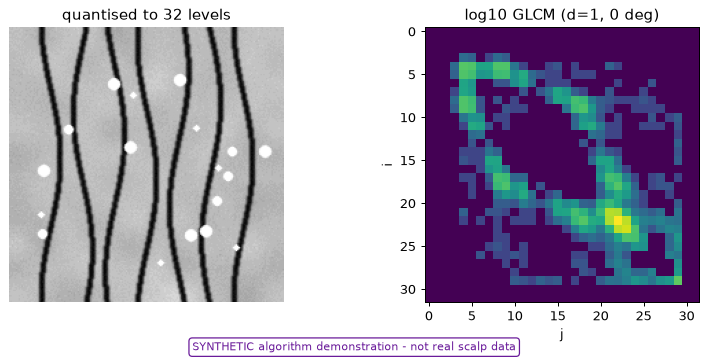

In [5]:
q = texture.quantize(gray, 32)
diffs = []
for d in cfg["texture"]["distances"]:
    for a in cfg["texture"]["angles_deg"]:
        mine, _ = texture.glcm(q, d, a, 32)
        ref = graycomatrix(q, [d], [np.deg2rad(a)], levels=32, symmetric=True, normed=True)[:, :, 0, 0]
        diffs.append(np.abs(mine - ref).max())
print(f"max |ours - skimage| over 12 offsets: {max(diffs):.2e}")
P, _ = texture.glcm(q, 1, 0, 32)
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(q, cmap="gray")
ax[0].set_title("quantised to 32 levels")
ax[0].axis("off")
ax[1].imshow(np.log10(P + 1e-6), cmap="viridis")
ax[1].set_title("log10 GLCM (d=1, 0 deg)")
ax[1].set_xlabel("j")
ax[1].set_ylabel("i")
plt.tight_layout()
save_fig(fig, "glcm_matrix", "synthetic")
plt.show()

## 2. Histogram entropy ≠ GLCM entropy
Shuffling the pixels of an image keeps its histogram — and therefore its **histogram entropy** — exactly, but
destroys spatial structure, which the **GLCM entropy** and contrast detect.

saved outputs/figures/03_texture_pyramids/synthetic/SYNTHETIC_entropy_shuffle_demo.png


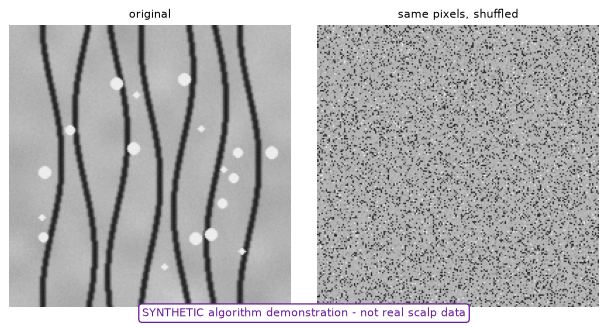

,image,hist_entropy_bits,glcm_entropy_bits_mean,glcm_contrast_mean,glcm_energy_mean,glcm_homogeneity_mean
0,original,5.6701,4.8404,20.4444,0.3059,0.6196
1,pixels shuffled,5.6701,5.7206,62.9865,0.2286,0.3998


In [6]:
shuffled = rng.permutation(gray.ravel()).reshape(gray.shape)
rows = []
for name, im in (("original", gray), ("pixels shuffled", shuffled)):
    agg = texture.glcm_features(im, 32)["aggregate"]
    rows.append(
        {
            "image": name,
            "hist_entropy_bits": texture.histogram_entropy(im),
            "glcm_entropy_bits_mean": agg["glcm_entropy_bits_mean"],
            "glcm_contrast_mean": agg["glcm_contrast_mean"],
            "glcm_energy_mean": agg["glcm_energy_mean"],
            "glcm_homogeneity_mean": agg["glcm_homogeneity_mean"],
        }
    )
fig = show_grid([gray, shuffled], ["original", "same pixels, shuffled"], ncols=2, size=3.5)
save_fig(fig, "entropy_shuffle_demo", "synthetic")
plt.show()
pd.DataFrame(rows).round(4)

## 3. Masks: valid pairs only
Filling the outside of a mask with zeros and then calling a whole-array GLCM creates an artificial edge. Our masked
GLCM counts only pairs whose two pixels are both valid; `interior_patches` is the alternative of using fully valid
squares.

In [7]:
from scalptrack.segmentation import segment_candidates

rgb = SYN["flakes"]["rgb"]
g = to_gray(rgb)
seg = segment_candidates(rgb, cfg)
scalp = seg["scalp"]
zero_filled = np.where(scalp, g, 0).astype(np.uint8)
a_masked = texture.glcm_features(g, 32, mask=scalp)["aggregate"]
a_zero = texture.glcm_features(zero_filled, 32)["aggregate"]
patches = texture.interior_patches(scalp, 24, 12)
a_patch = pd.DataFrame(
    [texture.glcm_features(g[y0:y1, x0:x1], 32)["aggregate"] for x0, y0, x1, y1 in patches]
).mean()
pd.DataFrame(
    {
        "masked valid pairs": a_masked,
        "zero-filled whole array (WRONG)": a_zero,
        f"mean of {len(patches)} interior 24px patches": a_patch,
    }
).loc[["glcm_contrast_mean", "glcm_energy_mean", "glcm_entropy_bits_mean", "glcm_homogeneity_mean"]].round(4)

,masked valid pairs,zero-filled whole array (WRONG),mean of 8 interior 24px patches
glcm_contrast_mean,1.9756,51.2798,0.5134
glcm_energy_mean,0.3866,0.3227,0.5398
glcm_entropy_bits_mean,3.5706,4.1719,2.2923
glcm_homogeneity_mean,0.7317,0.6717,0.8040


## 4. Feature table and distributions by label
Real development images are used when available; the synthetic three-class fixture always runs so the code path is
demonstrated. **Synthetic labels are not scalp conditions** and their CSV is stored separately.

In [8]:
samples = syn.synthetic_classification_set(n_sources_per_class=20, variants_per_source=1, seed=cfg["seed"])
t0 = time.perf_counter()
syn_feats = pd.DataFrame(
    [ft.extract_features(s["image"], cfg) | {"label": s["label"], "image_id": s["image_id"]} for s in samples]
)
print(f"{len(samples)} synthetic images, {len(ft.feature_names())} features, {time.perf_counter() - t0:.1f}s")
p = project_path(cfg, "results", NB, "SYNTHETIC_feature_table.csv", create=True)
syn_feats.to_csv(p, index=False)
print("saved", rel(p))
real_feats = None
if REAL:
    dev = development_images(cfg, n_per_class=8, max_total=200)
    real_feats = pd.DataFrame(
        [ft.extract_features(d["rgb"], cfg) | {"label": d["label"], "image_id": d["image_id"]} for d in dev]
    )
    p = project_path(cfg, "results", NB, "real_dev_feature_table.csv", create=True)
    real_feats.to_csv(p, index=False)
    print("saved", rel(p), "-", len(real_feats), "development images (train/validation only)")
pd.Series({g: len(v) for g, v in ft.FEATURE_GROUPS.items()}, name="features per group").to_frame()

60 synthetic images, 43 features, 1.4s
saved outputs/results/03_texture_pyramids/SYNTHETIC_feature_table.csv


saved outputs/results/03_texture_pyramids/real_dev_feature_table.csv - 80 development images (train/validation only)


,features per group
intensity,5
color,13
edge,8
texture_hist,1
texture_glcm,12
multiscale,4


saved outputs/figures/03_texture_pyramids/synthetic/SYNTHETIC_feature_distributions.png


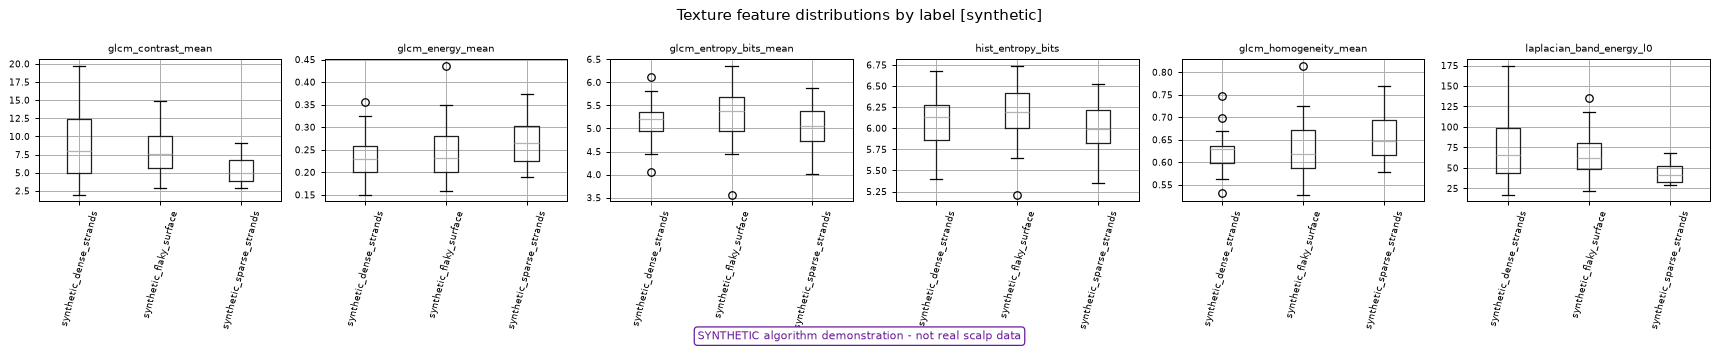

saved outputs/figures/03_texture_pyramids/real/feature_distributions.png


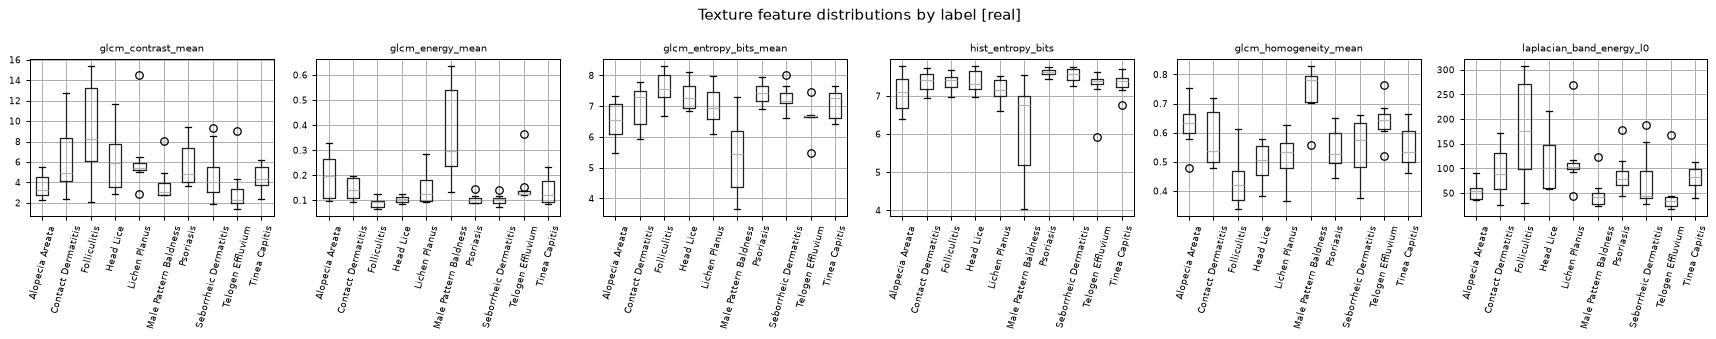

In [9]:
cols = [
    "glcm_contrast_mean",
    "glcm_energy_mean",
    "glcm_entropy_bits_mean",
    "hist_entropy_bits",
    "glcm_homogeneity_mean",
    "laplacian_band_energy_l0",
]
for table, prov in ((syn_feats, "synthetic"), (real_feats, "real")):
    if table is None:
        print("real feature distributions: skipped (dataset not available)")
        continue
    fig, axes = plt.subplots(1, len(cols), figsize=(3.2 * len(cols), 3.8))
    for ax, col in zip(axes, cols):
        table.boxplot(column=col, by="label", ax=ax, rot=75, fontsize=7)
        ax.set_title(col, fontsize=8)
        ax.set_xlabel("")
    fig.suptitle(f"Texture feature distributions by label [{prov}]")
    plt.tight_layout()
    save_fig(fig, "feature_distributions", prov)
    plt.show()

Contrast, energy and entropy are **statistical descriptors**, not validated scales of hydration, cleanliness or
health. Whether they help is measured, not assumed: notebook 05 runs the controlled comparison with vs without
the texture groups.

### 4.1 Computational cost

In [10]:
rows = []
big = cv2.resize(to_gray(SYN["clean"]["rgb"]), (512, 512))
for size in (128, 256, 512):
    im = cv2.resize(big, (size, size), interpolation=cv2.INTER_AREA)
    for levels in (16, 32, 64, 256):
        t0 = time.perf_counter()
        texture.glcm_features(im, levels)
        dt = time.perf_counter() - t0
        rows.append({"image_side_px": size, "levels": levels, "seconds_12_offsets": dt})
cost = pd.DataFrame(rows).pivot(index="levels", columns="image_side_px", values="seconds_12_offsets")
cost.round(4)

image_side_px,128,256,512
levels,,,
16,0.0028,0.0087,0.0621
32,0.0036,0.0072,0.0565
64,0.0066,0.0087,0.0629
256,0.0327,0.0347,0.0813


Cost grows with the number of pixel pairs (image area × 12 offsets) and the matrix size (levels²). With 256 levels
most GLCM entries are empty for small ROIs, which makes the statistics noisy — one reason for quantising to 32.

## 5. Lab 7 — Gaussian and Laplacian pyramids
Explicit destination sizes are used in `pyrDown`/`pyrUp`, so odd dimensions reconstruct exactly. Residuals are
signed float arrays.

saved outputs/figures/03_texture_pyramids/synthetic/SYNTHETIC_pyramids_flakes.png


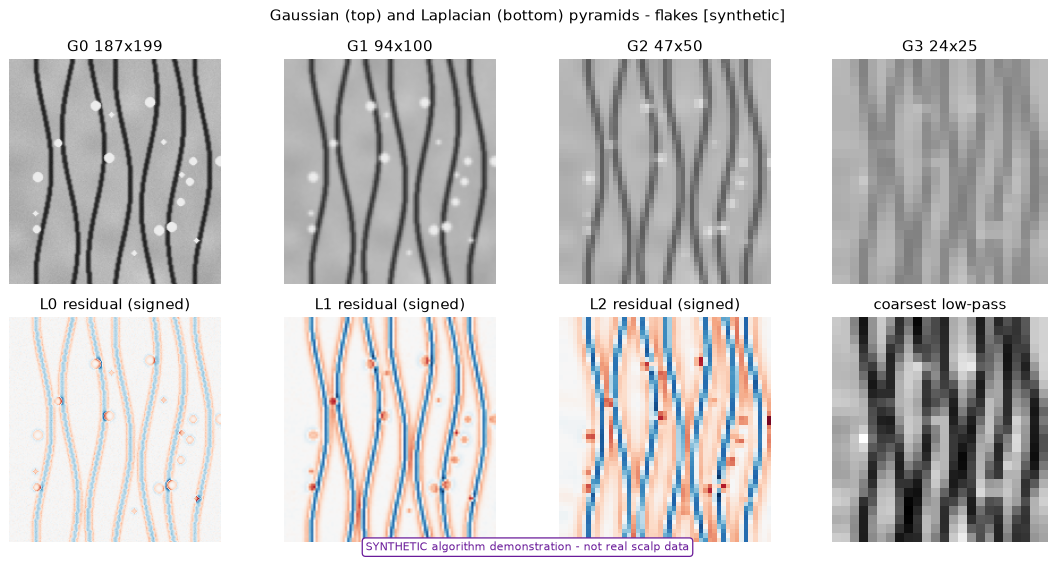

flakes: reconstruction max |error| = 0.00e+00, MSE = 0.00e+00 (intensity units)


,level,height,width,gauss_std,laplacian_energy,laplacian_abs_max
0,0,199,187,46.021,197.212,99.587
1,1,100,94,40.474,458.232,76.405
2,2,50,47,30.178,452.098,61.893
3,3,25,24,18.267,NaN,NaN


saved outputs/figures/03_texture_pyramids/real/pyramids_kaggle_hair_diseases_e69b7bc827ac.png


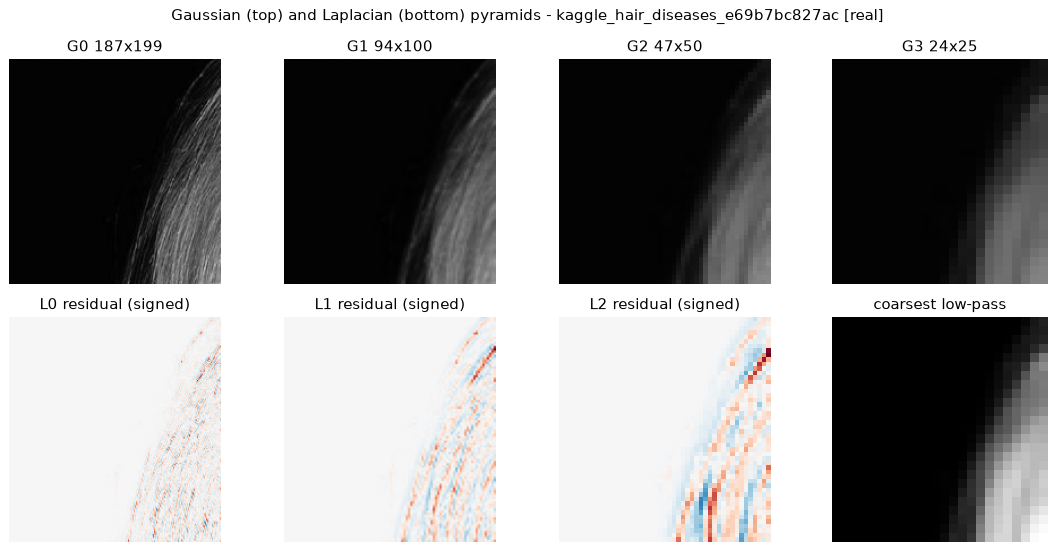

kaggle_hair_diseases_e69b7bc827ac: reconstruction max |error| = 0.00e+00, MSE = 0.00e+00 (intensity units)


,level,height,width,gauss_std,laplacian_energy,laplacian_abs_max
0,0,199,187,36.903,63.355,100.179
1,1,100,94,36.006,17.702,45.739
2,2,50,47,35.010,13.711,28.838
3,3,25,24,34.530,NaN,NaN


In [11]:
inputs = [(SYN["flakes"]["rgb"], "flakes", "synthetic")] + [
    (d["rgb"], d["image_id"], "real") for d in DEV[:1]
]
for rgb, name, prov in inputs:
    g = to_gray(rgb)[:199, :187]  # deliberately odd dimensions
    gp = pyramids.gaussian_pyramid(g, cfg["pyramids"]["max_levels"], cfg["pyramids"]["min_side_px"])
    lp = pyramids.laplacian_pyramid(gp)
    rec = pyramids.reconstruct(lp)
    fig, axes = plt.subplots(2, len(gp), figsize=(3.1 * len(gp), 6.2))
    for k in range(len(gp)):
        axes[0, k].imshow(gp[k], cmap="gray", vmin=0, vmax=255)
        axes[0, k].set_title(f"G{k} {gp[k].shape[1]}x{gp[k].shape[0]}")
        if k < len(gp) - 1:
            m = np.abs(lp[k]).max() or 1
            axes[1, k].imshow(lp[k], cmap="RdBu_r", vmin=-m, vmax=m)
            axes[1, k].set_title(f"L{k} residual (signed)")
        else:
            axes[1, k].imshow(lp[k], cmap="gray")
            axes[1, k].set_title("coarsest low-pass")
        axes[0, k].axis("off")
        axes[1, k].axis("off")
    fig.suptitle(f"Gaussian (top) and Laplacian (bottom) pyramids - {name} [{prov}]")
    plt.tight_layout()
    save_fig(fig, f"pyramids_{name}", prov)
    plt.show()
    err = pyramids.reconstruction_error(g, rec)
    tbl = pd.DataFrame(pyramids.pyramid_table(gp, lp))
    print(
        f"{name}: reconstruction max |error| = {err['max_abs_error']:.2e}, MSE = {err['mse']:.2e} (intensity units)"
    )
    display(tbl.round(3))

### 5.1 Thin detail disappears at coarse levels
Laplacian band energy per level for shafts of increasing width: thin (2 px) shafts live almost entirely in L0/L1
and are gone from coarse levels; wide shafts keep energy at coarser scales. Pyramids give multiscale views — they
do not recover detail the camera never resolved.

saved outputs/figures/03_texture_pyramids/synthetic/SYNTHETIC_band_energy_by_width.png


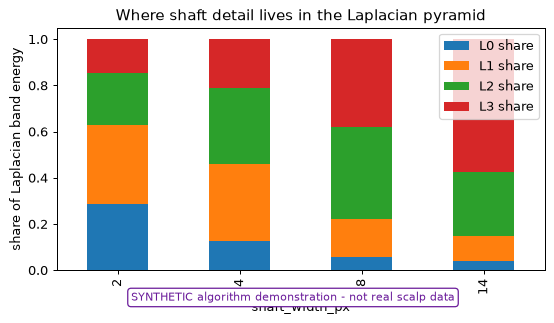

,L0 share,L1 share,L2 share,L3 share
shaft_width_px,,,,
2,0.287,0.343,0.226,0.145
4,0.127,0.334,0.329,0.210
8,0.057,0.164,0.399,0.381
14,0.042,0.104,0.279,0.575


In [12]:
rows = []
for w in (2, 4, 8, 14):
    im = to_gray(
        syn.render_hair_image(syn.straight_shafts(4, w, 90, size=256)["mask"], noise_sigma=0, seed=0)
    )
    e = pyramids.band_energies(pyramids.laplacian_pyramid(pyramids.gaussian_pyramid(im, 4, 16)))
    tot = sum(e)
    rows.append({"shaft_width_px": w, **{f"L{k} share": v / tot for k, v in enumerate(e)}})
bands = pd.DataFrame(rows).set_index("shaft_width_px")
ax = bands.plot.bar(stacked=True, figsize=(7, 3.5))
ax.set_ylabel("share of Laplacian band energy")
ax.set_title("Where shaft detail lives in the Laplacian pyramid")
save_fig(ax.figure, "band_energy_by_width", "synthetic")
plt.show()
bands.round(3)

## 6. Limitations
* GLCM features depend on quantisation, ROI size and resizing (features are computed on a 256×256 INTER_AREA copy
  for the classifier; measurements never use that copy).
* Texture differences between dataset folders may reflect camera, compression or lighting rather than condition.
* Pyramid band energies are scale descriptors; the coarsest levels of small ROIs carry few pixels.

## 7. Conclusion
GLCM contrast/energy/entropy and histogram entropy are implemented with explicit definitions, verified against
scikit-image, and exported in a fixed schema. Gaussian/Laplacian pyramids reconstruct exactly (float64 error at or below machine precision, see the error tables)
and quantify the scale at which hair detail exists. Code: `scalptrack.texture`, `scalptrack.pyramids`,
`scalptrack.features`.

**References:** scikit-image GLCM docs; OpenCV image pyramids tutorial (spec Section 24.2, refs 4–5).